# 🧠 Pelatihan Model PhishShield

Notebook ini melatih model ML kecil yang menilai **peluang phishing sebuah URL** dari ciri-ciri URL-nya (rancangan bagian 6), lalu mengekspornya ke `extension/model/model.json` supaya bisa dijalankan **langsung di browser**.

**Sebelum mulai:**
1. Install library: `pip install -r requirements.txt`
2. Dataset: kalau `data/processed/urls.csv` belum ada, sel **Muat dataset** otomatis mengunduh **PhiUSIIL** dari UCI (lewat `ucimlrepo`). Mau pakai atau menggabungkan dataset lain? Ubah `SOURCES` di sel itu, atau jalankan `prepare_data.py` dulu (lihat `ml/README.md`).
3. Jalankan semua sel dari atas ke bawah.

**Aturan emas:** hanya pakai fitur yang bisa dihitung ulang di ekstensi. Semua fitur di sini dihitung oleh `features.py`, kembaran `extension/features.js`.

In [1]:
import sys
import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

# Notebook bisa dibuka dari folder ml/ atau dari root repo
ML_DIR = Path.cwd() if (Path.cwd() / 'features.py').exists() else Path.cwd() / 'ml'
sys.path.insert(0, str(ML_DIR))

import features as F
import export_model as EX
import prepare_data as PD

DATA_PATH = ML_DIR / 'data' / 'processed' / 'urls.csv'
ARTIFACTS = ML_DIR / 'artifacts'
ARTIFACTS.mkdir(exist_ok=True)
RANDOM_STATE = 42

print('Folder ML :', ML_DIR)
print('Dataset   :', DATA_PATH)

Folder ML : /home/archer/Projects/phising-project-blocker/ml
Dataset   : /home/archer/Projects/phising-project-blocker/ml/data/processed/urls.csv


## 1. Muat dataset

Format: `url, label, source` dengan `label` 1 = phishing, 0 = legit (dibuat oleh `prepare_data.py`).

Sumber data (`SOURCES`):
- **PhiUSIIL** (UCI id 967): diunduh otomatis lewat `ucimlrepo` dan di-cache di `data/raw/`.
- **Kaggle "Malicious URLs dataset"** (`malicious_phish.csv`): **unduh manual** dari https://www.kaggle.com/datasets/sid321axn/malicious-urls-dataset lalu simpan ke `ml/data/raw/malicious_phish.csv`. Dataset ini dipakai karena URL legit-nya nyata dan banyak yang punya subdomain (`docs.`, `news.`, `en.`, ...), sedangkan legit PhiUSIIL hampir semuanya `https://www.domain`. Hanya URL **benign**-nya yang dipakai (preset `malicious-benign`): URL phishing Kaggle kebanyakan situs normal yang diretas dengan halaman phishing di path, sehingga di mode `'host'` labelnya menyesatkan (percobaan dengan URL phishing Kaggle: akurasi turun ke 63,6%).

`urls.csv` dibuat ulang otomatis kalau belum ada atau sumbernya berbeda dengan `SOURCES`. URL tanpa `http(s)://` **tidak** dibuang (`require_scheme=False`), karena URL Kaggle umumnya tanpa skema dan model tidak lagi memakai fitur yang bergantung pada skema (lihat bagian 2).

> Di PhiUSIIL asli **label 1 = legit, 0 = phishing** ("Label 1 corresponds to a legitimate URL, label 0 to a phishing URL"). `prepare_data.py` sudah membaliknya, jadi di sini **1 = phishing**.

In [2]:
# Sumber data (format sama dengan --source di prepare_data.py)
SOURCES = ['phiusiil:uci', 'malicious-benign:data/raw/malicious_phish.csv']

# Buat ulang urls.csv kalau belum ada atau sumbernya beda dengan SOURCES.
# balance=False: semua host legit dipakai (lebih beragam, false positive lebih rendah);
# ketimpangan kelas sudah diatasi class_weight='balanced' di bagian 4.
# Kalau mengubah balance, hapus dulu data/processed/urls.csv supaya dibuat ulang.
wanted = {s.split(':', 1)[0] for s in SOURCES}
if not DATA_PATH.exists() or set(pd.read_csv(DATA_PATH, usecols=['source'])['source'].unique()) != wanted:
    PD.prepare(SOURCES, DATA_PATH, require_scheme=False, balance=False, seed=RANDOM_STATE)

df = pd.read_csv(DATA_PATH, dtype={'url': str})
print(f'Jumlah URL: {len(df):,}')
print(pd.crosstab(df['source'], df['label'].map({0: 'legit', 1: 'phishing'}), margins=True, margins_name='total'))
df.sample(10, random_state=RANDOM_STATE)

[phiusiil] memakai cache /home/archer/Projects/phising-project-blocker/ml/data/raw/phiusiil_uci_967.csv (hapus file ini untuk mengunduh ulang)

[phiusiil] UCI id 967: 235,795 baris dipakai, 0 baris label lain dibuang
  contoh phishing: ['http://www.teramill.com', 'http://www.f0519141.xsph.ru', 'http://www.shprakserf.gq']
  contoh legit   : ['https://www.southbankmosaics.com', 'https://www.uni-mainz.de', 'https://www.voicefmradio.co.uk']

[malicious-benign] malicious_phish.csv: 428,103 baris dipakai, 223,088 baris label lain dibuang
  contoh phishing: []
  contoh legit   : ['mp3raid.com/music/krizz_kaliko.html', 'bopsecrets.org/rexroth/cr/1.htm', 'http://buzzfil.net/m/show-art/ils-etaient-loin-de-s-imaginer-que-le-hibou-allait-faire-ceci-quand-ils-filmaient-2.html']
448 URL duplikat dibuang
392,702 URL (59.2%) tanpa http(s)://
  ⚠️ Banyak URL tanpa skema: fitur IsHTTPS jadi tidak bisa dipercaya.
     Pakai --require-scheme, atau buang IsHTTPS dari FEATURES di train.ipynb.

Tersimpan: /h

,url,label,source
633892,https://lps.top-party-pet.com/alvn_7227_1_es_l...,1,phiusiil
286622,marketnews.ca/search/tag?query=wirelesswave,0,malicious-benign
628862,https://www.weok-design.de,0,phiusiil
529011,discussion.ketchikandailynews.com/article.php?...,0,malicious-benign
511985,etudehouseindo.com/0_themes/etude_jadi/action/...,0,malicious-benign
357756,twitter.com/KNBR,0,malicious-benign
269124,merritt.peralta.edu/student-resources/programs...,0,malicious-benign
3457,companydatabase.org/c/post-offices/post-office...,0,malicious-benign
292226,yellowpages.com/kansas-city-mo/dentists,0,malicious-benign
173017,gammadeltapsi.com/,0,malicious-benign


### Cek bias dataset

Kalau suatu pola sangat berbeda antara legit & phishing *hanya karena cara dataset dikumpulkan*, model akan belajar "jalan pintas" yang tidak berlaku di internet nyata.

Riwayat jalan pintas di proyek ini:
- **Path:** semua URL legit PhiUSIIL berbentuk `https://www.domain` tanpa path, sehingga model URL penuh menganggap `docs.python.org/3/library/...` berbahaya (±97%). Diatasi dengan **model berbasis host** (bagian 2).
- **Subdomain:** hanya ±6% host legit PhiUSIIL yang punya subdomain (setelah `www.` dibuang), sedangkan phishing ±55%. Akibatnya situs seperti `lifestyle.bisnis.com` (59%) dan `anireel.wondershare.com` (74%) kena banner saat demo. Diatasi dengan menambah URL legit nyata dari Kaggle.
- **HTTPS:** legit PhiUSIIL 100% https, sehingga semua situs `http://` dapat 92–100%. Diatasi dengan membuang `IsHTTPS` & `URLLength` (bagian 2).

Tabel di bawah dirinci per sumber. Yang penting: kolom **punya subdomain** untuk legit seharusnya tidak lagi mendekati 0%.

In [3]:
parsed = df['url'].str.extract(r'^(?:(?P<scheme>[a-zA-Z]+)://)?(?P<host>[^/?#]*)(?P<rest>.*)$').fillna('')
host = parsed['host'].str.lower().str.split('@').str[-1].str.split(':').str[0]
bare = host.str.replace(r'^www\.', '', regex=True)
bias = pd.DataFrame({
    'sumber': df['source'],
    'label': df['label'].map({0: 'legit', 1: 'phishing'}),
    'punya path/query (%)': parsed['rest'].str.len() > 1,
    'diawali www. (%)': host.str.startswith('www.'),
    'https (%)': parsed['scheme'].str.lower() == 'https',
    'punya subdomain (%)': [h != F.get_registrable_domain(h) for h in bare],
})
(bias.groupby(['sumber', 'label']).mean() * 100).round(1)

punya path/query (%)  diawali www. (%)  https (%)  \
sumber           label                                                         
malicious-benign legit                     88.9               3.1        0.5   
phiusiil         legit                      0.0             100.0      100.0   
                 phishing                  28.4              41.5       48.6   

                           punya subdomain (%)  
sumber           label                          
malicious-benign legit                    22.9  
phiusiil         legit                     5.3  
                 phishing                 39.7

## 2. Pilih cakupan URL, fitur & ekstrak

`URL_SCOPE` menentukan bagian URL mana yang dinilai model. Nilainya ikut disimpan ke `model.json`, supaya ekstensi memakai cara yang sama:

| `URL_SCOPE` | Yang dinilai | Kapan dipakai |
|---|---|---|
| `'host'` ✅ | `skema://host/` saja, awalan `www.` dibuang. Path & query diabaikan. | Dataset seperti PhiUSIIL, yang URL legit-nya tidak pernah punya path. Model fokus ke ciri **nama domain** (IP, tanda hubung, subdomain, panjang), cocok untuk domain phishing baru (zero-day). |
| `'full'` | Seluruh URL | Hanya kalau data legit juga punya banyak URL dengan path. |

Contoh mode `'host'`: `https://www.its.ac.id/informatika/id/beranda/` dinilai sebagai `https://its.ac.id/`.

URL diubah jadi angka oleh `features.extract_features()`, yang meniru normalisasi URL di browser (huruf kecil, punycode, port default dibuang, dll.), jadi angkanya sama dengan yang dihitung ekstensi dari `location.href`.

In [4]:
URL_SCOPE = 'host'  # 'host' atau 'full' (lihat tabel di atas)

# Fitur dari rancangan (bagian 6.2), disesuaikan dengan data gabungan. Semuanya bisa
# dihitung ulang di extension/features.js.
# - IsHTTPS dibuang: legit PhiUSIIL 100% https dan URL Kaggle tidak punya skema, jadi fitur
#   ini hanya mengajari model asal dataset ("http = phishing"), bukan ciri phishing.
# - URLLength diganti HostLength: di mode 'host', URLLength ikut menghitung panjang
#   "http://" vs "https://", sehingga info skema bocor lagi.
FEATURES = ['NumDots', 'HasIP', 'SubdomainCount', 'HasAtSymbol', 'NumHyphens', 'HostLength']

# Fitur tambahan: angka di nama host (phishing PhiUSIIL 36% punya angka, legit ±3-6%), punycode,
# dan hosting gratis (web.app, weebly.com, ...: 29,5% host phishing vs 2,5% legit).
# Di mode 'host', PathLength & NumQueryParams selalu konstan → jangan dipakai.
FEATURES += ['NumDigits', 'HasPunycode', 'IsFreeHosting']

print('Cakupan URL  :', URL_SCOPE)
print('Fitur dipakai:', FEATURES)

Cakupan URL  : host
Fitur dipakai: ['NumDots', 'HasIP', 'SubdomainCount', 'HasAtSymbol', 'NumHyphens', 'HostLength', 'NumDigits', 'HasPunycode', 'IsFreeHosting']


In [5]:
rows = F.extract_many(df['url'], URL_SCOPE)
# Kunci = host tanpa skema: model tidak memakai skema, jadi http://x dan https://x adalah host yang sama
keys = [k.split('://', 1)[1] if k else None for k in F.canonical_many(df['url'], URL_SCOPE)]
valid = np.array([r is not None for r in rows])
print(f'URL gagal diparse (dibuang): {(~valid).sum():,}')

feat_df = pd.DataFrame([r for r in rows if r is not None], index=df.index[valid])
data = pd.concat([df.loc[valid, ['url', 'label']], feat_df], axis=1)
data['key'] = pd.Series(keys, index=df.index)[valid]

# Di mode 'host', URL berbeda dari host yang sama punya fitur identik. Satukan per host,
# supaya host yang sama tidak muncul di data latih DAN data uji (hasil evaluasi jadi terlalu bagus).
# Host yang muncul sebagai legit sekaligus phishing dibuang karena labelnya bertentangan.
n_label = data.groupby('key')['label'].nunique()
conflict_keys = n_label[n_label > 1].index
before = len(data)
data = data[~data['key'].isin(conflict_keys)].drop_duplicates(subset='key')
print(f'Disatukan per {URL_SCOPE}: {before - len(data):,} baris dibuang '
      f'({len(conflict_keys):,} berlabel ganda), sisa {len(data):,}')
print(data['label'].map({0: 'legit (0)', 1: 'phishing (1)'}).value_counts())

X = data[FEATURES].astype(np.int64)
y = data['label'].astype(int)

# Rata-rata tiap fitur per kelas: fitur yang bagus nilainya beda jauh antara legit & phishing
data.groupby('label')[F.FEATURE_NAMES].mean().T.rename(columns={0: 'rata-rata legit', 1: 'rata-rata phishing'})

URL gagal diparse (dibuang): 0
Disatukan per host: 316,947 baris dibuang (86 berlabel ganda), sisa 346,503
label
legit (0)       262284
phishing (1)     84219
Name: count, dtype: int64


label,rata-rata legit,rata-rata phishing
URLLength,26.011430,31.663971
NumDots,1.329425,1.753429
HasIP,0.000095,0.001864
SubdomainCount,0.227909,0.504162
HasAtSymbol,0.000000,0.000119
NumHyphens,0.122051,0.566915
IsHTTPS,0.500286,0.446455
HostLength,17.510302,23.213859
PathLength,1.000000,1.000000
NumDigits,0.319143,2.055474


## 3. Bagi data latih & uji

In [6]:
X_train, X_test, y_train, y_test, url_train, url_test = train_test_split(
    X, y, data['url'], test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f'Data latih: {len(X_train):,}  |  Data uji: {len(X_test):,}')

Data latih: 277,202  |  Data uji: 69,301


## 4. Latih model

Dua kandidat sesuai rancangan:
- **Decision Tree**: satu pohon, paling mudah dijelaskan, file kecil.
- **Random Forest**: banyak pohon, biasanya lebih akurat, file lebih besar.

`max_depth`, `n_estimators`, dan `min_samples_leaf` menentukan ukuran `model.json`. Usahakan di bawah ±5 MB supaya ringan di browser.

In [7]:
models = {
    'Decision Tree': DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=20, class_weight='balanced', random_state=RANDOM_STATE
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=60, max_depth=12, min_samples_leaf=10,
        class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE
    ),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    n_nodes = sum(e.tree_.node_count for e in EX.estimators_of(m))
    print(f'✓ {name} selesai dilatih ({n_nodes:,} node)')

✓ Decision Tree selesai dilatih (325 node)
✓ Random Forest selesai dilatih (44,618 node)


## 5. Evaluasi

Jangan hanya melihat akurasi (rancangan 6.4):
- **Precision**: dari semua yang dianggap phishing, berapa yang benar phishing.
- **Recall**: dari semua phishing, berapa yang tertangkap.
- **False positive rate**: situs aman yang salah dianggap berbahaya. Bikin pengguna kesal, harus serendah mungkin.
- **False negative rate**: phishing yang lolos. Ini bahaya sebenarnya.

In [8]:
def positive_proba(model, X):
    return model.predict_proba(X)[:, EX.positive_index(model)]


def evaluate(model, X, y, threshold=0.5):
    proba = positive_proba(model, X)
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        'accuracy': accuracy_score(y, pred),
        'precision': precision_score(y, pred, zero_division=0),
        'recall': recall_score(y, pred, zero_division=0),
        'f1': f1_score(y, pred, zero_division=0),
        'roc_auc': roc_auc_score(y, proba),
        'false_positive_rate': fp / (fp + tn) if fp + tn else 0.0,
        'false_negative_rate': fn / (fn + tp) if fn + tp else 0.0,
    }


results = pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in models.items()}).T
results.style.format('{:.4f}')

,accuracy,precision,recall,f1,roc_auc,false_positive_rate,false_negative_rate
Decision Tree,0.8201,0.6533,0.5534,0.5992,0.7938,0.0943,0.4466
Random Forest,0.8189,0.6459,0.5639,0.6021,0.7981,0.0993,0.4361


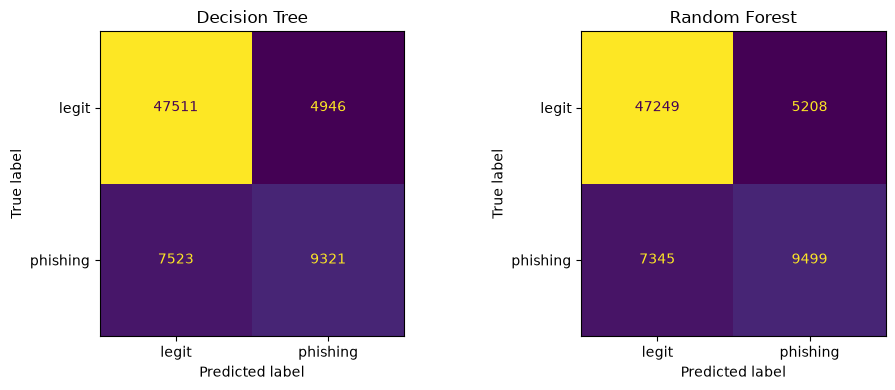

In [9]:
fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4))
for ax, (name, m) in zip(np.atleast_1d(axes), models.items()):
    ConfusionMatrixDisplay.from_estimator(
        m, X_test, y_test, display_labels=['legit', 'phishing'], ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 6. Pilih model

Pilih yang false positive rate-nya rendah dengan recall yang masih bagus.

In [10]:
CHOSEN = 'Random Forest'  # ganti ke 'Decision Tree' kalau ingin model paling sederhana
model = models[CHOSEN]
print(f'Model terpilih: {CHOSEN}')
print()
print(classification_report(y_test, model.predict(X_test), target_names=['legit', 'phishing'], digits=4))

Model terpilih: Random Forest

              precision    recall  f1-score   support

       legit     0.8655    0.9007    0.8827     52457
    phishing     0.6459    0.5639    0.6021     16844

    accuracy                         0.8189     69301
   macro avg     0.7557    0.7323    0.7424     69301
weighted avg     0.8121    0.8189    0.8145     69301



## 7. Analisis ambang (threshold)

Di ekstensi, skor risiko = peluang × 100 (dibulatkan), lalu:

| Skor | Level |
|---|---|
| < `warn` | 🟢 Aman, tanpa gangguan |
| ≥ `warn` | 🟡 Waspada: banner kecil, form mulai dipantau |
| ≥ `danger` | 🔴 Berbahaya |

Titik awal rancangan: `warn = 40`, `danger = 70`. Tabel di bawah menunjukkan dampak tiap ambang pada data uji.

Catatan: ekstensi juga menambah poin heuristik (redirect, link pendek, umur domain) di atas skor model, lihat `extension/config.js`.

In [11]:
proba_test = positive_proba(model, X_test)
y_true = y_test.to_numpy()
score_test = np.floor(proba_test * 100 + 0.5)  # sama dengan Math.round di JavaScript

rows = []
for t in range(30, 95, 5):
    pred = (score_test >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    rows.append({
        'ambang (%)': t,
        'false positive rate': fp / (fp + tn) if fp + tn else 0.0,
        'recall (phishing tertangkap)': tp / (tp + fn) if tp + fn else 0.0,
        'precision': tp / (tp + fp) if tp + fp else np.nan,
    })
pd.DataFrame(rows).set_index('ambang (%)').style.format('{:.4f}')

,false positive rate,recall (phishing tertangkap),precision
ambang (%),,,
30,0.6294,0.8826,0.3105
35,0.4200,0.7938,0.3777
40,0.2028,0.6588,0.5105
45,0.1744,0.6363,0.5395
50,0.1117,0.5767,0.6238
55,0.0526,0.5098,0.7567
60,0.0391,0.4914,0.8013
65,0.0301,0.4736,0.8349
70,0.0171,0.4458,0.8932


In [12]:
# Saran ambang berdasarkan batas false positive yang masih bisa diterima
TARGET_FPR_WARN = 0.05    # maksimal 5% situs legit mendapat banner Waspada
TARGET_FPR_DANGER = 0.01  # maksimal 1% situs legit mendapat label Berbahaya

legit_scores = score_test[y_true == 0]
suggest_warn = int(np.clip(np.quantile(legit_scores, 1 - TARGET_FPR_WARN) + 1, 1, 99))
suggest_danger = int(np.clip(max(np.quantile(legit_scores, 1 - TARGET_FPR_DANGER) + 1, suggest_warn + 1), 2, 100))
print(f'Saran ambang: warn = {suggest_warn}, danger = {suggest_danger}')

# 45/75 (titik awal rancangan 40/70) supaya lebih sedikit false positive. Ganti dengan saran di atas kalau setuju.
THRESHOLDS = {'warn': 45, 'danger': 75}
# THRESHOLDS = {'warn': suggest_warn, 'danger': suggest_danger}
print('Ambang yang akan diekspor:', THRESHOLDS)

Saran ambang: warn = 56, danger = 76
Ambang yang akan diekspor: {'warn': 45, 'danger': 75}


## 8. Fitur paling berpengaruh

Berguna sebagai bahan penjelasan ke juri.

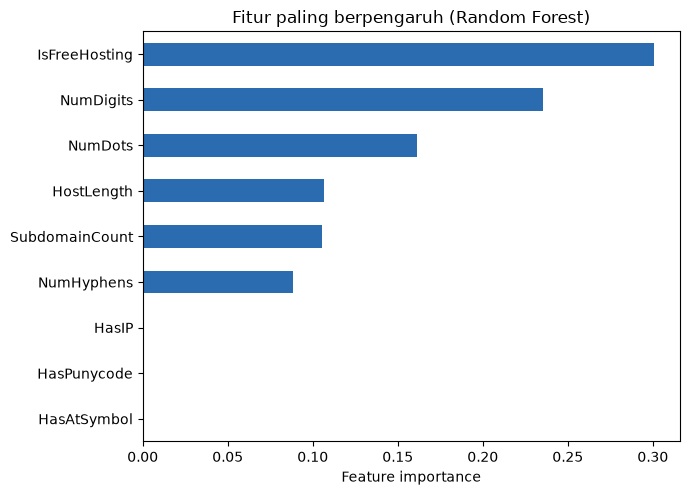

In [13]:
importance = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
ax = importance.plot.barh(figsize=(7, 0.45 * len(FEATURES) + 1), color='#2b6cb0')
ax.set_xlabel('Feature importance')
ax.set_title(f'Fitur paling berpengaruh ({CHOSEN})')
plt.tight_layout()
plt.show()

## 9. Uji dengan URL di luar dataset

Dataset sering tidak mewakili kondisi nyata (rancangan bagian 15). Metrik di bagian 5 hanya mengukur data yang polanya sama dengan data latih, jadi **tabel ini lebih jujur** untuk menilai false positive di dunia nyata. Tambahkan URL dari kampus/instansimu sendiri.

Kolom *dinilai sebagai* menunjukkan URL yang benar-benar dilihat model (di mode `'host'` hanya skema + host).

Pembanding dari model sebelumnya (`c79eecd155bc`, PhiUSIIL saja, dengan `IsHTTPS`): `news.ycombinator.com` 59, `bpjs-kesehatan.go.id` 67, `id.wikipedia.org` 36, `docs.python.org` 34. Setelah data Kaggle ditambah dan `IsHTTPS` dibuang, URL legit bersubdomain seharusnya turun, sementara contoh phishing tetap tinggi.

In [14]:
SANITY_URLS = {
    # Legit dengan path panjang / subdomain / tanpa www: jangan sampai dianggap phishing
    'https://www.its.ac.id/informatika/id/beranda/': 0,
    'https://github.com/scikit-learn/scikit-learn/blob/main/README.rst': 0,
    'https://id.wikipedia.org/wiki/Institut_Teknologi_Sepuluh_Nopember': 0,
    'https://docs.python.org/3/library/urllib.parse.html#url-parsing': 0,
    'https://www.tokopedia.com/search?st=product&q=laptop%20gaming': 0,
    'https://news.ycombinator.com/item?id=1': 0,
    'https://bpjs-kesehatan.go.id/': 0,
    'https://scikit-learn.org/stable/modules/tree.html': 0,
    # Pola mencurigakan (contoh buatan, bukan situs nyata)
    'http://192.168.10.5/login/verify.php': 1,
    'http://secure-login-bank-update.example-verify.com/account/confirm': 1,
    'https://login.secure.account.verify.example.xyz/signin?session=8f7a6c': 1,
    'http://bank.example@203.0.113.7/login': 1,
    'http://login-kampus-verifikasi.free-host.test:8000/fake-login/': 1,
}

sanity = EX.features_frame(SANITY_URLS, FEATURES, URL_SCOPE)
sanity_proba = positive_proba(model, sanity)
pd.DataFrame({
    'url': list(SANITY_URLS),
    'dinilai sebagai': F.canonical_many(SANITY_URLS, URL_SCOPE),
    'harapan': ['phishing' if v else 'legit' for v in SANITY_URLS.values()],
    'skor model (%)': np.floor(sanity_proba * 100 + 0.5).astype(int),
})

,url,dinilai sebagai,harapan,skor model (%)
0,https://www.its.ac.id/informatika/id/beranda/,https://its.ac.id/,legit,18
1,https://github.com/scikit-learn/scikit-learn/b...,https://github.com/,legit,37
2,https://id.wikipedia.org/wiki/Institut_Teknolo...,https://id.wikipedia.org/,legit,51
3,https://docs.python.org/3/library/urllib.parse...,https://docs.python.org/,legit,51
4,https://www.tokopedia.com/search?st=product&q=...,https://tokopedia.com/,legit,35
5,https://news.ycombinator.com/item?id=1,https://news.ycombinator.com/,legit,49
6,https://bpjs-kesehatan.go.id/,https://bpjs-kesehatan.go.id/,legit,14
7,https://scikit-learn.org/stable/modules/tree.html,https://scikit-learn.org/,legit,45
8,http://192.168.10.5/login/verify.php,http://192.168.10.5/,phishing,90
9,http://secure-login-bank-update.example-verify...,http://secure-login-bank-update.example-verify...,phishing,69


## 10. Simpan & ekspor ke ekstensi

Sel di bawah menyimpan `artifacts/model.joblib`, lalu menulis:
- `extension/model/model.json`: model yang dijalankan di browser
- `extension/model/test_vectors.json`: contoh URL + hasil Python, untuk dicocokkan di halaman uji ekstensi

Sebelum menulis, hasil JSON dicek harus sama persis dengan scikit-learn.

In [15]:
metrics = {k: round(float(v), 4) for k, v in evaluate(model, X_test, y_test).items()}
bundle = {
    'model': model,
    'features': FEATURES,
    'url_scope': URL_SCOPE,
    'thresholds': THRESHOLDS,
    'metrics': metrics,
    'dataset': {
        'file': DATA_PATH.name,
        'n_train': int(len(X_train)),
        'n_test': int(len(X_test)),
        'phishing_ratio': round(float(y.mean()), 4),
    },
    'created_at': datetime.datetime.now().isoformat(timespec='seconds'),
}
joblib.dump(bundle, ARTIFACTS / 'model.joblib')
print('Tersimpan:', ARTIFACTS / 'model.joblib')
metrics

Tersimpan: /home/archer/Projects/phising-project-blocker/ml/artifacts/model.joblib


{'accuracy': 0.8189,
 'precision': 0.6459,
 'recall': 0.5639,
 'f1': 0.6021,
 'roc_auc': 0.7981,
 'false_positive_rate': 0.0993,
 'false_negative_rate': 0.4361}

In [16]:
verify_X = X_test.sample(n=min(len(X_test), 2000), random_state=RANDOM_STATE)
payload = EX.export_bundle(bundle, verify_X=verify_X)

legit_urls = url_test[y_test == 0]
phish_urls = url_test[y_test == 1]
vector_urls = (
    legit_urls.sample(n=min(100, len(legit_urls)), random_state=RANDOM_STATE).tolist()
    + phish_urls.sample(n=min(100, len(phish_urls)), random_state=RANDOM_STATE).tolist()
    + list(SANITY_URLS)
)
EX.write_test_vectors(bundle, payload, vector_urls)

✓ Verifikasi JSON vs scikit-learn: 2,021 baris, selisih maks 2.22e-16
✓ Model tersimpan: /home/archer/Projects/phising-project-blocker/extension/model/model.json (933 KB, 60 pohon, 44,618 node, url_scope host, model_id d9ea1c75dee7)
✓ Test vector tersimpan: /home/archer/Projects/phising-project-blocker/extension/model/test_vectors.json (233 URL)


## 11. Langkah berikutnya

1. Buka `chrome://extensions` lalu klik ⟳ (reload) pada PhishShield.
2. Klik ikon PhishShield → **Pengaturan & model** → **Uji kecocokan model**. Semua baris harus cocok.
3. Coba skenario di `demo/README.md`, lalu buka situs-situs normal untuk mengecek false positive.
4. Kalau false positive terlalu banyak: naikkan ambang, tambah whitelist, atau latih ulang dengan data legit yang lebih beragam.